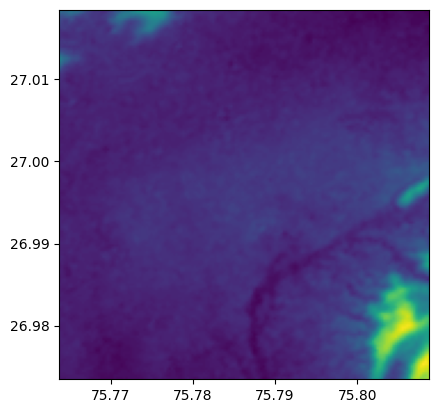

In [1]:
import matplotlib.pyplot as plt
import rasterio
from rasterio.plot import show

# Open and plot with geographic coordinates on the axes
with rasterio.open('jaipur_SRTMGL1.tif') as src:
    show(src)

In [23]:
import numpy as np
import rasterio

UNDERPASSES = [
    {"name": "WTP Underpass", "lat": 26.8225, "lon": 75.8120, "drop_m": 2.5},
    {"name": "Jagatpura Flyover Underpass", "lat": 26.8150, "lon": 75.8350, "drop_m": 2.0},
]



def apply_underpass_depressions(dem, dem_transform, underpasses=None):
    if underpasses is None:
        underpasses = [
            {"name": "WTP Underpass", "lat": 26.8225, "lon": 75.8120, "drop_m": 2.5},
            {"name": "Jagatpura Flyover", "lat": 26.8150, "lon": 75.8350, "drop_m": 2.0},
        ]
        
    modified_data = np.array(dem).astype(np.float32)
    mask = np.zeros_like(modified_data, dtype=bool)
    height, width = modified_data.shape

    for site in underpasses:
        r, c = rasterio.transform.rowcol(dem_transform, site["lon"], site["lat"])
        if 0 <= r < height and 0 <= c < width:
            r0, r1 = max(0, r - 1), min(height, r + 2)
            c0, c1 = max(0, c - 1), min(width, c + 2)
            modified_data[r0:r1, c0:c1] -= site["drop_m"]
            mask[r0:r1, c0:c1] = True

    # Reconstruct the PySheds Raster
    modified_raster = modified_data.view(type(dem))
    modified_raster.viewfinder = getattr(dem, 'viewfinder', None)
    
    # CRITICAL FIX: Ensure metadata is an iterable dictionary to prevent update() crashes
    original_meta = getattr(dem, 'metadata', {})
    modified_raster.metadata = original_meta if original_meta is not None else {}
    
    return modified_raster, mask

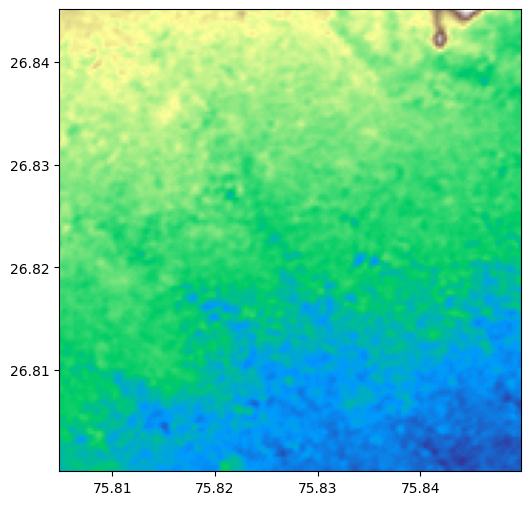

In [2]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt


with rasterio.open('jaipur_SRTMGL1.tif') as src:
    data = src.read(1).astype(float)
    bounds = src.bounds

plt.figure(figsize=(8,6))
im = plt.imshow(data, cmap='terrain', extent=[bounds.left, bounds.right, bounds.bottom, bounds.top])

Saved flow_accumulation.png


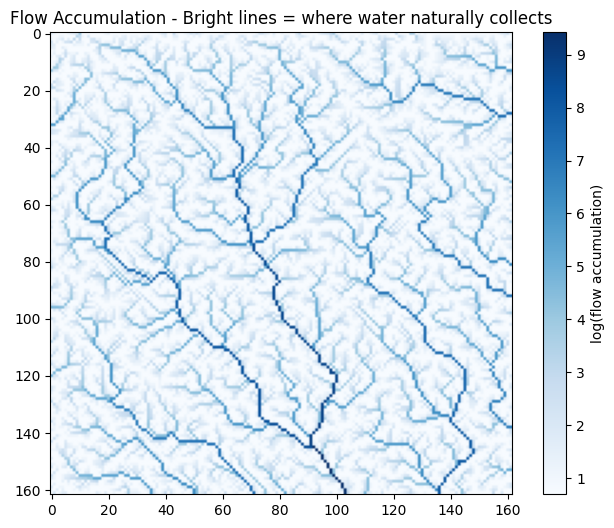

In [3]:
"""
Just the flow accumulation visualization (the blue drainage lines).
Put output_SRTMGL1.tif in the same folder as this script, then run it.
"""

import numpy as np
np.in1d = np.isin  # compatibility fix for pysheds + newer numpy

from pysheds.grid import Grid
import matplotlib.pyplot as plt

DEM_PATH = "jaipur_SRTMGL1.tif"  # change if your file is named differently

# Load the DEM and clean up fake pits/depressions/flats so flow calculation works correctly
grid = Grid.from_raster(DEM_PATH)
dem = grid.read_raster(DEM_PATH)
pit_filled = grid.fill_pits(dem)
flooded = grid.fill_depressions(pit_filled)
inflated = grid.resolve_flats(flooded)

# flowdir: which direction water flows from each pixel
# accumulation: how much upstream water passes through each pixel (high = channel/drain path)
fdir = grid.flowdir(inflated)
acc = np.array(grid.accumulation(fdir))

# log1p scaling: accumulation values range from ~1 to over 10,000, so without a log
# scale only the single biggest channel would be visible and everything else would
# look pure black. log1p makes both small and large channels visible together.
plt.figure(figsize=(8, 6))
im = plt.imshow(np.log1p(acc), cmap='Blues')
plt.colorbar(im, label='log(flow accumulation)')
plt.title('Flow Accumulation - Bright lines = where water naturally collects')
plt.savefig('flow_accumulation.png', dpi=150, bbox_inches='tight')
print("Saved flow_accumulation.png")
plt.show()

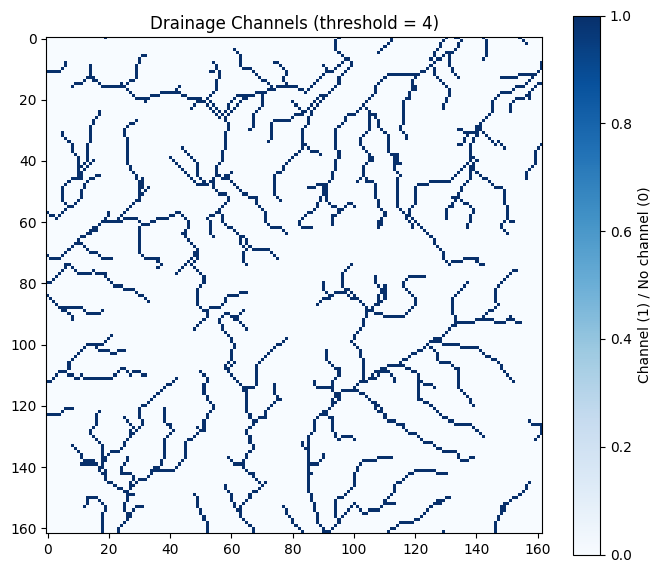

Saved drainage_channels.png
Percent of area classified as channel: 8.52%


In [4]:
import numpy as np
import matplotlib.pyplot as plt

# your flow accumulation array should already exist as something like `flow_acc`
# if it's already log-transformed for plotting, work on the raw values instead

log_flow = np.log1p(acc)   # log1p = log(1+x), avoids errors on zero values

# --- pick your threshold here ---
threshold = 4   # try 4, 5, 6 and see what looks clean

# create a mask: True where flow is above threshold, False elsewhere
channel_mask = log_flow > threshold

# plot it
plt.figure(figsize=(8, 7))
plt.imshow(channel_mask, cmap='Blues')
plt.title(f"Drainage Channels (threshold = {threshold})")
plt.colorbar(label="Channel (1) / No channel (0)")
plt.savefig("drainage_channels.png", dpi=150)
plt.show()

print("Saved drainage_channels.png")
print(f"Percent of area classified as channel: {channel_mask.mean()*100:.2f}%")

Saved slope.png
Min slope: 0.00°, Max slope: 26.71°, Mean: 1.89°


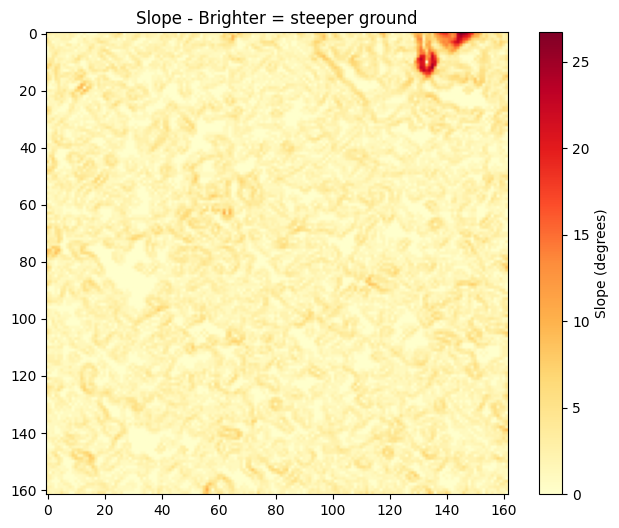

In [4]:
# --- SLOPE: how steep the ground is at each point ---
# Convert pixel size from degrees to meters (DEM is in lat/lon degrees, not meters)
latitude = 28.63  # approximate center latitude of your pilot area
meters_per_degree_lat = 111320
meters_per_degree_lon = 111320 * np.cos(np.radians(latitude))

cellsize_deg = grid.affine[0]  # pixel width in degrees
cellsize_x_m = cellsize_deg * meters_per_degree_lon
cellsize_y_m = cellsize_deg * meters_per_degree_lat

dem_array = np.array(inflated)
dzdy, dzdx = np.gradient(dem_array, cellsize_y_m, cellsize_x_m)
slope = np.sqrt(dzdx**2 + dzdy**2)
slope_degrees = np.degrees(np.arctan(slope))

plt.figure(figsize=(8, 6))
im = plt.imshow(slope_degrees, cmap='YlOrRd')
plt.colorbar(im, label='Slope (degrees)')
plt.title('Slope - Brighter = steeper ground')
plt.savefig('slope.png', dpi=150, bbox_inches='tight')
print("Saved slope.png")
print(f"Min slope: {slope_degrees.min():.2f}°, Max slope: {slope_degrees.max():.2f}°, Mean: {slope_degrees.mean():.2f}°")

plt.show()

C:\Users\Work\AppData\Local\Temp\ipykernel_8224\3538026341.py:35: UserWarning: Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  roads["geometry"] = roads.geometry.buffer(buffer_degrees)


Saved imperviousness.tif
Percent of area covered by roads/buildings: 36.03%
Saved imperviousness.png


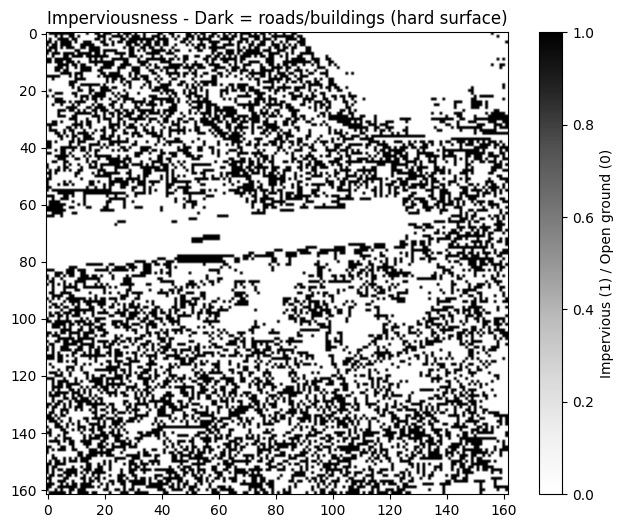

In [5]:
"""
Build an imperviousness layer from buildings.geojson and roads.geojson,
aligned to the same grid as your DEM (output_SRTMGL1.tif).
"""
import geopandas as gpd
import rasterio
from rasterio import features
import numpy as np
import matplotlib.pyplot as plt

DEM_PATH = "jaipur_SRTMGL1.tif"
BUILDINGS_PATH = "jaipur_buildings.geojson"
ROADS_PATH = "roads.geojson"
ROAD_BUFFER_METERS = 5  # assume an average road is ~5m wide since OSM roads are just lines, not shapes

# --- Load the DEM just to copy its grid shape and coordinate system ---
with rasterio.open(DEM_PATH) as src:
    dem_shape = src.shape          # (height, width) — should be (162, 184)
    dem_transform = src.transform  # maps pixel positions to real lat/lon coordinates
    dem_crs = src.crs              # coordinate system (EPSG:4326, same as before)

# --- Load buildings and roads ---
buildings = gpd.read_file(BUILDINGS_PATH)
roads = gpd.read_file(ROADS_PATH)

# Make sure both are in the same coordinate system as the DEM
buildings = buildings.to_crs(dem_crs)
roads = roads.to_crs(dem_crs)

# Roads come in as thin lines with no width — give them a real width by
# buffering them out a few meters on each side (turns lines into thin rectangles)
# Note: buffer distance needs to be in degrees here since we're in EPSG:4326.
# ~0.00005 degrees is roughly 5 meters at this latitude.
buffer_degrees = ROAD_BUFFER_METERS / 111320
roads["geometry"] = roads.geometry.buffer(buffer_degrees)

# --- Stamp buildings onto the grid: 1 where a building exists, 0 elsewhere ---
building_mask = features.rasterize(
    [(geom, 1) for geom in buildings.geometry if geom is not None],
    out_shape=dem_shape,
    transform=dem_transform,
    fill=0,
    dtype="uint8"
)

# --- Stamp roads onto the grid the same way ---
road_mask = features.rasterize(
    [(geom, 1) for geom in roads.geometry if geom is not None],
    out_shape=dem_shape,
    transform=dem_transform,
    fill=0,
    dtype="uint8"
)

# --- Combine: a pixel is "impervious" if it's EITHER a building OR a road ---
impervious_mask = np.maximum(building_mask, road_mask)

# --- Save as its own GeoTIFF so it lines up with your DEM for later steps ---
with rasterio.open(
    "imperviousness.tif", "w",
    driver="GTiff",
    height=dem_shape[0], width=dem_shape[1],
    count=1, dtype="uint8",
    crs=dem_crs, transform=dem_transform
) as dst:
    dst.write(impervious_mask, 1)

print("Saved imperviousness.tif")
print(f"Percent of area covered by roads/buildings: {impervious_mask.mean()*100:.2f}%")

# --- Visualize ---
plt.figure(figsize=(8, 6))
plt.imshow(impervious_mask, cmap="Greys")
plt.title("Imperviousness - Dark = roads/buildings (hard surface)")
plt.colorbar(label="Impervious (1) / Open ground (0)")
plt.savefig("imperviousness.png", dpi=150, bbox_inches="tight")
print("Saved imperviousness.png")
plt.show()

In [24]:
"""
Updated scenario generator utilizing historical rainfall records
and artificial depression modeling for flyover underpasses.
"""
import csv
import numpy as np
import rasterio
import pandas as pd
from pysheds.grid import Grid

DEM_PATH = "jaipur_SRTMGL1.tif"
IMPERVIOUS_PATH = "imperviousness.tif"
HISTORICAL_RAINFALL_CSV = "jaipur_malviyanagar_rainfall.csv"  # Format: date, rainfall_mm

# ============================================================
# STEP 1: Load DEM & Extract Transform
# ============================================================
grid = Grid.from_raster(DEM_PATH)
dem = grid.read_raster(DEM_PATH)
elevation = dem.astype(np.float32)
height, width = elevation.shape

# Extract transform to correctly map lat/lon coordinates
with rasterio.open(DEM_PATH) as src:
    dem_transform = src.transform

def latlon_to_pixel(lat, lon):
    row, col = rasterio.transform.rowcol(dem_transform, lon, lat)
    return row, col

# ============================================================
# STEP 2: Inject Artificial Depressions (Underpasses)
# ============================================================
modified_elevation, underpass_mask = apply_underpass_depressions(dem, dem_transform)
# STEP 3: Hydrological Routing (PySheds)
# ============================================================
pit_filled = grid.fill_pits(modified_elevation)
flooded = grid.fill_depressions(pit_filled)
inflated = grid.resolve_flats(flooded)

fdir = grid.flowdir(inflated)
acc = np.array(grid.accumulation(fdir))
log_acc = np.log1p(acc)
elevation_final = np.array(inflated)

# ============================================================
# STEP 4: Topographic Calculations (Jaipur Latitude)
# ============================================================
latitude = 26.82  # Adjusted for Jaipur
meters_per_degree_lat = 111320
meters_per_degree_lon = 111320 * np.cos(np.radians(latitude))
cellsize_deg = grid.affine[0]
cellsize_x_m = cellsize_deg * meters_per_degree_lon
cellsize_y_m = cellsize_deg * meters_per_degree_lat

# Use modified_elevation to preserve underpass steepness
dzdy, dzdx = np.gradient(modified_elevation, cellsize_y_m, cellsize_x_m)
slope = np.sqrt(dzdx**2 + dzdy**2)
slope_degrees = np.degrees(np.arctan(slope))
slope_factor = 1 / (1 + slope_degrees / 10)

# ============================================================
# STEP 5: Imperviousness & Drainage Estimation
# ============================================================
with rasterio.open(IMPERVIOUS_PATH) as src:
    imperviousness = src.read(1).astype(float)

def normalize(arr):
    valid = arr[np.isfinite(arr)]
    return (arr - valid.min()) / (valid.max() - valid.min() + 1e-9)

flow_norm = normalize(log_acc)
channel_mask = (log_acc > 4).astype(float)

drainage_capacity_estimated = np.where(
    channel_mask == 1,
    10 + flow_norm * 40,
    5
)

# Cripple the drainage at the underpasses
drainage_capacity_estimated[underpass_mask] = 2.0 

# ============================================================
# STEP 6: Load Historical Rainfall Data
# ============================================================
history_df = pd.read_csv(HISTORICAL_RAINFALL_CSV)
active_rainfall_values = history_df[history_df["rainfall_mm"] > 1.0]["rainfall_mm"].values

# ============================================================
# STEP 7: Generate Scenarios (Memory-Optimized Export)
# ============================================================
csv_filename = "training_data_historical.csv"
headers = ["elevation", "slope_deg", "flow_accum", "imperviousness", 
           "drainage_capacity_estimated", "rainfall_mm", "flood_depth_cm"]

# Initialize CSV with headers
with open(csv_filename, 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(headers)

# Flatten static variables once to conserve memory
flat_elev = elevation_final.flatten().astype(np.float32)
flat_slope = slope_degrees.flatten().astype(np.float32)
flat_accum = log_acc.flatten().astype(np.float32)
flat_imperv = imperviousness.flatten().astype(np.float32)
flat_drain = drainage_capacity_estimated.flatten().astype(np.float32)

for rainfall_mm in active_rainfall_values:
    # 1. Stochastic drainage clogging (drains randomly lose 20-40% capacity)
    clog_factor = np.random.uniform(0.6, 1.0, size=imperviousness.shape)
    effective_drainage = drainage_capacity_estimated * clog_factor

    raw_runoff_cm = (
        rainfall_mm
        * 0.15
        * (0.4 + 0.6 * imperviousness)
        * (0.3 + 0.7 * flow_norm)
        * slope_factor
    )

    drainage_relief_cm = np.minimum(effective_drainage * 0.15, 8)
    base_depth = np.maximum(0, raw_runoff_cm - drainage_relief_cm)

    # 2. Proportional micro-topography noise
    micro_chaos = np.random.normal(0, 0.12 * (base_depth + 0.1), size=base_depth.shape)
    flood_depth_cm = np.maximum(0, base_depth + micro_chaos)

    # Construct the iteration's dataset and append to disk immediately
    chunk_df = pd.DataFrame({
        "elevation": flat_elev,
        "slope_deg": flat_slope,
        "flow_accum": flat_accum,
        "imperviousness": flat_imperv,
        "drainage_capacity_estimated": flat_drain,
        "rainfall_mm": rainfall_mm,
        "flood_depth_cm": flood_depth_cm.flatten().astype(np.float32),
    })
    
    chunk_df.to_csv(csv_filename, mode='a', header=False, index=False)

print(f"Data generation complete. Exported {len(active_rainfall_values)} scenarios to {csv_filename}.")

Data generation complete. Exported 351 scenarios to training_data_historical.csv.


Training on 7369315 rows, testing on 1842329 rows
Training complete.

--- Model Performance on Unseen Test Data ---
MAE  (Mean Absolute Error):        0.016 cm
RMSE (Root Mean Squared Error):    0.043 cm
R²   (R-squared, fit quality):     0.962

--- Feature Importance ---
imperviousness                 0.744207
rainfall_mm                    0.189456
drainage_capacity_estimated    0.029425
flow_accum                     0.026730
slope_deg                      0.009815
elevation                      0.000367
dtype: float32

Saved feature_importance.png
Saved model.pkl


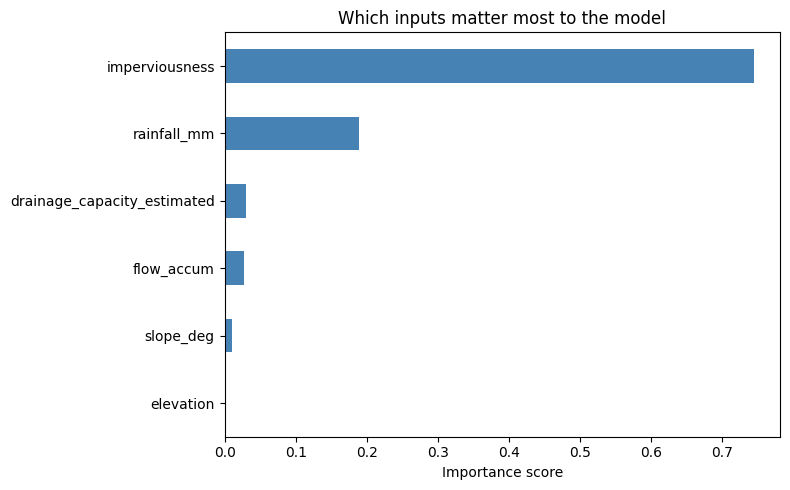

In [25]:
"""
Trains an XGBoost model to predict flood depth (cm) from terrain,
drainage, and rainfall features. Saves the trained model to disk.
"""
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
import matplotlib.pyplot as plt
import pickle

# ============================================================
# STEP 1: Load the training data
# ============================================================
df = pd.read_csv("training_data_historical.csv") # or your generated training data csv

# Features = the inputs the model learns from
# Target = the thing we're trying to predict
feature_columns = [
    "elevation",
    "slope_deg",
    "flow_accum",
    "imperviousness",
    "drainage_capacity_estimated",
    "rainfall_mm",
]
target_column = "flood_depth_cm"

# FIXED: Filter 'df' directly instead of undefined 'training_data'
# df = df[df["flood_depth_cm"] > 0.1]

X = df[feature_columns]   
y = df[target_column]
# ============================================================
# STEP 2: Split into training data and testing data
# ============================================================
# We hold back 20% of the data that the model NEVER sees while learning,
# so we can honestly check afterward how well it predicts on new/unseen rows.
# random_state=42 just makes the split repeatable every time you run this.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training on {len(X_train)} rows, testing on {len(X_test)} rows")

# ============================================================
# STEP 3: Train the XGBoost model
# ============================================================
# XGBoost (Extreme Gradient Boosting) builds many small decision trees one
# after another, where each new tree focuses on fixing the mistakes the
# previous trees made. n_estimators = how many trees to build.
model = xgb.XGBRegressor(
    n_estimators=300,       # number of trees to build
    max_depth=6,            # how many questions deep each tree can go
    learning_rate=0.05,     # how much each new tree corrects previous mistakes
    subsample=0.8,          # each tree trains on 80% of rows (adds robustness)
    colsample_bytree=0.8,   # each tree considers 80% of features (adds robustness)
    random_state=42,
    n_jobs=-1                # use all available CPU cores to train faster
)

model.fit(X_train, y_train)
print("Training complete.")

# ============================================================
# STEP 4: Evaluate on the held-back test data
# ============================================================
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n--- Model Performance on Unseen Test Data ---")
print(f"MAE  (Mean Absolute Error):        {mae:.3f} cm")
print(f"RMSE (Root Mean Squared Error):    {rmse:.3f} cm")
print(f"R²   (R-squared, fit quality):     {r2:.3f}")

# ============================================================
# STEP 5: Which features actually mattered most?
# ============================================================
importance = pd.Series(model.feature_importances_, index=feature_columns)
importance = importance.sort_values(ascending=False)

print("\n--- Feature Importance ---")
print(importance)

plt.figure(figsize=(8, 5))
importance.plot(kind="barh", color="steelblue")
plt.title("Which inputs matter most to the model")
plt.xlabel("Importance score")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150)
print("\nSaved feature_importance.png")

# ============================================================
# STEP 6: Save the trained model to disk
# ============================================================
with open("model.pkl", "wb") as f:
    pickle.dump(model, f)

print("Saved model.pkl")

In [9]:
model.score(X_test,y_test)

0.9635284908076814

In [8]:
"""
Runs the trained model across the South Jaipur grid (Malviya Nagar / Jagatpura)
for a heavy rainfall event, then plots results as colored circles on a Folium map.
"""
import numpy as np
np.in1d = np.isin
from pysheds.grid import Grid
import rasterio
import pickle
import pandas as pd
import folium

# ============================================================
# STEP 1: Rebuild layers for South Jaipur (Malviya Nagar / Jagatpura)
# ============================================================
DEM_PATH = "jaipur_SRTMGL1.tif"  # Update with your South Jaipur DEM
IMPERVIOUS_PATH = "imperviousness.tif"



grid = Grid.from_raster(DEM_PATH)

dem = grid.read_raster(DEM_PATH)

with rasterio.open(DEM_PATH) as src:
    dem_transform = src.transform
    
modified_elevation, underpass_mask = apply_underpass_depressions(dem, dem_transform)

pit_filled = grid.fill_pits(modified_elevation)
flooded = grid.fill_depressions(pit_filled)
inflated = grid.resolve_flats(flooded)
fdir = grid.flowdir(inflated)
acc = np.array(grid.accumulation(fdir))
log_acc = np.log1p(acc)
elevation = np.array(inflated)

# pit_filled = grid.fill_pits(dem)
# flooded = grid.fill_depressions(pit_filled)
# inflated = grid.resolve_flats(flooded)
# fdir = grid.flowdir(inflated)
# acc = np.array(grid.accumulation(fdir))
# log_acc = np.log1p(acc)
# elevation = np.array(inflated)

# Center latitude for South Jaipur (Malviya Nagar / Jagatpura)
latitude_center = 26.8225
m_per_deg_lat = 111320
m_per_deg_lon = 111320 * np.cos(np.radians(latitude_center))
cellsize_deg = grid.affine[0]
dzdy, dzdx = np.gradient(elevation, cellsize_deg * m_per_deg_lat, cellsize_deg * m_per_deg_lon)
slope_degrees = np.degrees(np.arctan(np.sqrt(dzdx**2 + dzdy**2)))

with rasterio.open(IMPERVIOUS_PATH) as src:
    imperviousness = src.read(1).astype(float)
    dem_shape = src.shape
    dem_transform = src.transform

def normalize(arr):
    valid = arr[np.isfinite(arr)]
    return (arr - valid.min()) / (valid.max() - valid.min() + 1e-9)

flow_norm = normalize(log_acc)
channel_mask = (log_acc > 4).astype(float)

drainage_capacity_estimated = np.where(
    channel_mask == 1,
    10 + flow_norm * 40,
    5
)

drainage_capacity_estimated[underpass_mask] = 2.0

# ============================================================
# STEP 2: Load the trained model
# ============================================================
with open("model.pkl", "rb") as f:
    model = pickle.load(f)

# ============================================================
# STEP 3: Predict flood depth across South Jaipur grid
# ============================================================
# 102.6 mm was recorded near Jaipur Airport / Sanganer during the major storm
RAINFALL_MM = 102.6   

height, width = dem_shape

all_rows = pd.DataFrame({
    "elevation": elevation.flatten(),
    "slope_deg": slope_degrees.flatten(),
    "flow_accum": log_acc.flatten(),
    "imperviousness": imperviousness.flatten(),
    "drainage_capacity_estimated": drainage_capacity_estimated.flatten(),
    "rainfall_mm": RAINFALL_MM,
})

predictions = model.predict(all_rows)
predictions = np.clip(predictions, 0, None)  # No negative flood depths
flood_grid = predictions.reshape(height, width)

print(f"Predicted {height*width} points. Max flood depth: {flood_grid.max():.2f} cm")

# ============================================================
# STEP 4: Convert pixel positions to real lat/lon
# ============================================================
def pixel_to_latlon(row, col):
    lon, lat = rasterio.transform.xy(dem_transform, row, col)
    return lat, lon

# ============================================================
# STEP 5: Build map centered on South Jaipur (Jagatpura / Malviya Nagar)
# ============================================================
center_lat, center_lon = 26.8225, 75.8275  # Midpoint of xmin=75.8050, ymin=26.8000, xmax=75.8500, ymax=26.8450
flood_map = folium.Map(location=[center_lat, center_lon], zoom_start=14)

STEP = 4   # Downsample grid for interactive rendering speed

def get_color(depth_cm):
    if depth_cm < 0.5:
        return "green"     # Low risk
    elif depth_cm < 2.0:
        return "orange"    # Moderate risk
    else:
        return "red"       # Severe risk

for row in range(0, height, STEP):
    for col in range(0, width, STEP):
        depth = float(flood_grid[row, col])
        if depth < 0.1:    # Skip dry pixels
            continue

        lat, lon = pixel_to_latlon(row, col)
        lat, lon = float(lat), float(lon)

        folium.CircleMarker(
            location=[lat, lon],
            radius=2 + depth * 1.5,
            color=get_color(depth),
            fill=True,
            fill_opacity=0.6,
            popup=f"Flood depth: {depth:.2f} cm"
        ).add_to(flood_map)

# Add prominent landmarks for presentation clarity
folium.Marker(
    [26.8225, 75.8120], 
    popup="World Trade Park / Malviya Nagar Sector 9",
    icon=folium.Icon(color="blue", icon="info-sign")
).add_to(flood_map)

folium.Marker(
    [26.8280, 75.8060], 
    popup="Jawahar Circle / JLN Marg Junction",
    icon=folium.Icon(color="blue", icon="info-sign")
).add_to(flood_map)

flood_map.save("jaipur_south_flood_map.html")
print("Saved jaipur_south_flood_map.html — open in browser")

Predicted 26244 points. Max flood depth: 5.37 cm
Saved jaipur_south_flood_map.html — open in browser


In [26]:
"""
Validates the trained model against a real, documented flooding event in South Jaipur:
August 1, 2024 — Severe waterlogging across Jawahar Circle, WTP / JLN Marg,
Jagatpura flyover underpasses, and Jaipur Airport (source: HT / PTI / Media Reports).

Steps:
1. Pull real rainfall for South Jaipur (Open-Meteo historical API)
2. Map target locations to grid pixels
3. Predict flood depths using the real event rainfall
4. Compare spot depths against the grid average
"""
import numpy as np
np.in1d = np.isin
from pysheds.grid import Grid
import rasterio
import pickle
import pandas as pd
import requests

DEM_PATH = "jaipur_SRTMGL1.tif"
IMPERVIOUS_PATH = "imperviousness.tif"

# ============================================================
# STEP 1: Fetch REAL rainfall for August 1, 2024 (South Jaipur / Airport)
# ============================================================
url = "https://archive-api.open-meteo.com/v1/archive"
params = {
    "latitude": 26.8225,
    "longitude": 75.8275,
    "start_date": "2024-08-01",
    "end_date": "2024-08-01",
    "hourly": "precipitation",
    "timezone": "Asia/Kolkata"
}

response = requests.get(url, params=params)
data = response.json()

hourly_rain = data["hourly"]["precipitation"]
peak_hourly_rainfall = max(hourly_rain)    # Worst hourly intensity
daily_total_rain = sum(hourly_rain)        # Cumulative day rain

print(f"Real Rainfall on August 1, 2024 (South Jaipur / Sanganer Zone):")
print(f"  Peak Hourly Rain: {peak_hourly_rainfall:.2f} mm/hr")
print(f"  Daily Total Rain: {daily_total_rain:.2f} mm")

# ============================================================
# STEP 2: Rebuild terrain & hydrology layers for South Jaipur
# ============================================================
with rasterio.open(DEM_PATH) as src:
    dem_transform = src.transform

    
modified_elevation, underpass_mask = apply_underpass_depressions(elevation, dem_transform)


grid = Grid.from_raster(DEM_PATH)
dem = grid.read_raster(DEM_PATH)

pit_filled = grid.fill_pits(modified_elevation)
flooded = grid.fill_depressions(pit_filled)
inflated = grid.resolve_flats(flooded)
fdir = grid.flowdir(inflated)
acc = np.array(grid.accumulation(fdir))
log_acc = np.log1p(acc)
elevation = np.array(inflated)

# pit_filled = grid.fill_pits(dem)
# flooded = grid.fill_depressions(pit_filled)
# inflated = grid.resolve_flats(flooded)
# fdir = grid.flowdir(inflated)
# acc = np.array(grid.accumulation(fdir))
# log_acc = np.log1p(acc)
# elevation = np.array(inflated)

latitude_center = 26.8225
m_per_deg_lat = 111320
m_per_deg_lon = 111320 * np.cos(np.radians(latitude_center))
cellsize_deg = grid.affine[0]
dzdy, dzdx = np.gradient(elevation, cellsize_deg * m_per_deg_lat, cellsize_deg * m_per_deg_lon)
slope_degrees = np.degrees(np.arctan(np.sqrt(dzdx**2 + dzdy**2)))

with rasterio.open(IMPERVIOUS_PATH) as src:
    imperviousness = src.read(1).astype(float)
    dem_shape = src.shape
    dem_transform = src.transform

def normalize(arr):
    valid = arr[np.isfinite(arr)]
    return (arr - valid.min()) / (valid.max() - valid.min() + 1e-9)

flow_norm = normalize(log_acc)
channel_mask = (log_acc > 4).astype(float)

drainage_capacity_estimated = np.where(
    channel_mask == 1,
    10 + flow_norm * 40,
    5
)
drainage_capacity_estimated[underpass_mask] = 2.0

# ============================================================
# STEP 3: Load trained XGBoost model
# ============================================================
with open("model.pkl", "rb") as f:
    model = pickle.load(f)

# ============================================================
# STEP 4: Predict flood depth for EVERY pixel using event rainfall
# ============================================================
height, width = dem_shape

all_rows = pd.DataFrame({
    "elevation": elevation.flatten(),
    "slope_deg": slope_degrees.flatten(),
    "flow_accum": log_acc.flatten(),
    "imperviousness": imperviousness.flatten(),
    "drainage_capacity_estimated": drainage_capacity_estimated.flatten(),
    "rainfall_mm": daily_total_rain,   # Using real documented total rainfall
})

predictions = model.predict(all_rows)
predictions = np.clip(predictions, 0, None)
flood_grid = predictions.reshape(height, width)

area_average_depth = flood_grid.mean()
print(f"\nArea-wide average predicted flood depth: {area_average_depth:.2f} cm")

# ============================================================
# STEP 5: Convert real lat/lon to raster pixel row/col
# ============================================================
def latlon_to_pixel(lat, lon):
    row, col = rasterio.transform.rowcol(dem_transform, lon, lat)
    return row, col

# Documented waterlogging points across Jagatpura / Malviya Nagar / Airport corridor
known_flood_locations = {
    "Jawahar Circle / JLN Marg Junction": (26.8280, 75.8060),
    "World Trade Park (WTP) Underpass": (26.8225, 75.8120),
    "Jagatpura Railway Flyover Underpass": (26.8150, 75.8350),
    "Jaipur Airport Entrance Terminal": (26.8242, 75.8033),
    "Pratap Nagar Sector 8 Low Basin": (26.8020, 75.8210)
}

# ============================================================
# STEP 6: Validate predicted depth against area baseline
# ============================================================
print("\n--- Validation against documented South Jaipur flooding (Aug 1, 2024) ---")
for name, (lat, lon) in known_flood_locations.items():
    row, col = latlon_to_pixel(lat, lon)

    if 0 <= row < height and 0 <= col < width:
        predicted_depth = flood_grid[row, col]
        difference = predicted_depth - area_average_depth
        print(f"\n{name}:")
        print(f"  Predicted depth: {predicted_depth:.2f} cm")
        print(f"  Area average:    {area_average_depth:.2f} cm")
        print(f"  Difference:      {'+' if difference >= 0 else ''}{difference:.2f} cm "
              f"({'HIGHER' if difference > 0 else 'LOWER'} than average)")
    else:
        print(f"\n{name}: falls outside current grid boundary")

Real Rainfall on August 1, 2024 (South Jaipur / Sanganer Zone):
  Peak Hourly Rain: 5.50 mm/hr
  Daily Total Rain: 24.30 mm

Area-wide average predicted flood depth: 0.17 cm

--- Validation against documented South Jaipur flooding (Aug 1, 2024) ---

Jawahar Circle / JLN Marg Junction:
  Predicted depth: 0.77 cm
  Area average:    0.17 cm
  Difference:      +0.60 cm (HIGHER than average)

World Trade Park (WTP) Underpass:
  Predicted depth: 0.55 cm
  Area average:    0.17 cm
  Difference:      +0.39 cm (HIGHER than average)

Jagatpura Railway Flyover Underpass:
  Predicted depth: 0.13 cm
  Area average:    0.17 cm
  Difference:      -0.04 cm (LOWER than average)

Jaipur Airport Entrance Terminal: falls outside current grid boundary

Pratap Nagar Sector 8 Low Basin:
  Predicted depth: 0.00 cm
  Area average:    0.17 cm
  Difference:      -0.17 cm (LOWER than average)


In [1]:
import geopandas as gpd
import folium

gdf = gpd.read_file("jaipur_buildings.geojson")

center = [
    gdf.geometry.centroid.y.mean(),
    gdf.geometry.centroid.x.mean()
]

m = folium.Map(
    location=center,
    zoom_start=14,
    tiles="OpenStreetMap"
)

folium.GeoJson(
    gdf,
    name="Buildings"
).add_to(m)

folium.LayerControl().add_to(m)

m.save("jaipur_buildings_map.html")

print("Buildings:", len(gdf))
print("Saved as jaipur_buildings_map.html")

C:\Users\Work\AppData\Local\Temp\ipykernel_8224\835940832.py:7: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gdf.geometry.centroid.y.mean(),
C:\Users\Work\AppData\Local\Temp\ipykernel_8224\835940832.py:8: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gdf.geometry.centroid.x.mean()


Buildings: 31049
Saved as jaipur_buildings_map.html


# gathering historical rainfall data


In [6]:
import requests
import pandas as pd

# Updated coordinates: Center of Malviya Nagar / Jawahar Circle bounding box
LATITUDE = 26.8225
LONGITUDE = 75.8275

# Historical date range
START_DATE = "2021-01-01"
END_DATE = "2025-12-31"

# Open-Meteo Historical Archive API endpoint
url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": LATITUDE,
    "longitude": LONGITUDE,
    "start_date": START_DATE,
    "end_date": END_DATE,
    "daily": "precipitation_sum",
    "timezone": "auto"
}

print(f"Fetching historical rainfall data for Malviya Nagar / Jagatpura zone ({LATITUDE}, {LONGITUDE})...")
response = requests.get(url, params=params)

if response.status_code == 200:
    data = response.json()
    
    # Extract daily dates and precipitation values
    daily_data = data.get("daily", {})
    dates = daily_data.get("time", [])
    precipitation = daily_data.get("precipitation_sum", [])
    
    # Construct a clean DataFrame
    df = pd.DataFrame({
        "date": dates,
        "rainfall_mm": precipitation
    })
    
    # Drop rows with missing values if any
    df = df.dropna()
    
    # Save to CSV
    csv_filename = "jaipur_malviyanagar_rainfall.csv"
    df.to_csv(csv_filename, index=False)
    
    print(f"Success! Saved {len(df)} records to {csv_filename}")
    print("\nTop 10 Heavy Rainfall Events in Dataset:")
    print(df.sort_values(by="rainfall_mm", ascending=False).head(10))
else:
    print(f"Failed to fetch data. Error code: {response.status_code}")
    print(response.text)

Fetching historical rainfall data for Malviya Nagar / Jagatpura zone (26.8225, 75.8275)...
Success! Saved 1826 records to jaipur_malviyanagar_rainfall.csv

Top 10 Heavy Rainfall Events in Dataset:
            date  rainfall_mm
210   2021-07-30         72.5
1655  2025-07-14         72.0
138   2021-05-19         58.1
899   2023-06-19         55.2
1695  2025-08-23         53.3
645   2022-10-08         50.7
211   2021-07-31         48.0
1323  2024-08-16         45.7
1671  2025-07-30         39.6
1343  2024-09-05         39.0
